Эпизод 200  | средняя награда за 100 эп.: -25.09 | ε = 0.367
Эпизод 400  | средняя награда за 100 эп.: -18.95 | ε = 0.135
Эпизод 600  | средняя награда за 100 эп.: -17.22 | ε = 0.050
Эпизод 800  | средняя награда за 100 эп.: -17.09 | ε = 0.050
Эпизод 1000 | средняя награда за 100 эп.: -16.92 | ε = 0.050
Эпизод 1200 | средняя награда за 100 эп.: -16.87 | ε = 0.050
Эпизод 1400 | средняя награда за 100 эп.: -16.88 | ε = 0.050
Эпизод 1600 | средняя награда за 100 эп.: -16.84 | ε = 0.050
Эпизод 1800 | средняя награда за 100 эп.: -16.86 | ε = 0.050
Эпизод 2000 | средняя награда за 100 эп.: -16.87 | ε = 0.050


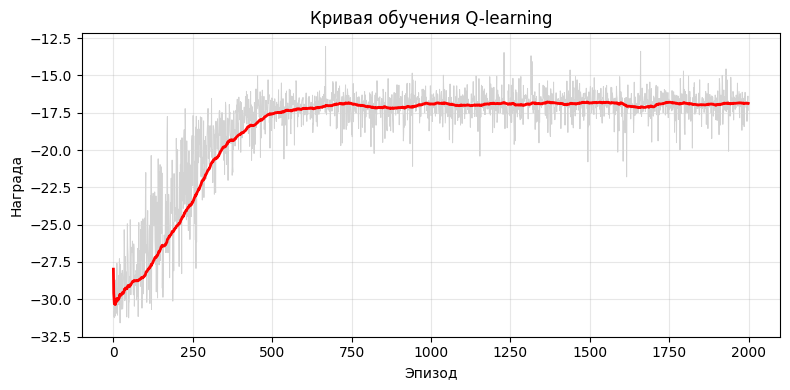


ВЫУЧЕННАЯ ПОЛИТИКА (K - сохранить, S - переключить):

Фаза 0
S K S S K
K K K K K
K K K K K
K K K K K
S S S S S

Фаза 1
K K K K S
K K K K S
S K K S S
K K K K K
K K K K K


In [2]:
# Импорт библиотеки NumPy для работы с массивами
import numpy as np

# Импорт модуля random для генерации случайных чисел
import random

# Импорт библиотеки Matplotlib для построения графиков
import matplotlib.pyplot as plt

# Фиксация случайного зерна для воспроизводимости результатов
random.seed(42)
np.random.seed(42)

# Количество дискретных уровней очереди
buckets = 5

# Функция дискретизации длины очереди
def disc(queue):
    # Очередь от 0 до 15 переводится в уровень от 0 до 4
    return min(buckets - 1, queue // 3)

# Функция, моделирующая один такт работы перекрёстка
def env_step(qn, qe, phase, action):
    # Если агент решил переключить светофор
    if action == 1:
        # Фаза меняется на противоположную
        phase = 1 - phase
        # В такт переключения автомобили не проезжают
        passed = 0
    else:
        # Если зелёный свет горит для направления Север–Юг
        if phase == 0:
            # Случайно определяется число проехавших автомобилей
            passed = min(qn, random.choices([0, 1, 2, 3], [0.1, 0.3, 0.4, 0.2])[0])
            # Уменьшение очереди на направлении NS
            qn -= passed
        # Если зелёный свет горит для направления Восток–Запад
        else:
            passed = min(qe, random.choices([0, 1, 2, 3], [0.1, 0.3, 0.4, 0.2])[0])
            # Уменьшение очереди на направлении EW
            qe -= passed

    # Прибытие новых автомобилей на направление NS
    qn = min(15, qn + random.choice([0, 1, 1, 2]))
    # Прибытие новых автомобилей на направление EW
    qe = min(15, qe + random.choice([0, 1, 1, 2]))

    # Награда равна минус суммарной длине очередей
    reward = -(qn + qe)

    # Если фаза была переключена, назначается дополнительный штраф
    if action == 1:
        reward -= 5

    # Возврат нового состояния среды и награды
    return qn, qe, phase, reward

# Создание Q-таблицы: очередь NS, очередь EW, фаза светофора, действие
Q = np.zeros((buckets, buckets, 2, 2))

# Скорость обучения
alpha = 0.2
# Коэффициент дисконтирования
gamma = 0.95
# Количество эпизодов обучения
episodes = 2000
# Количество тактов управления в одном эпизоде
steps = 100

# Список для хранения средней награды каждого эпизода
rewards = []

# Начальная вероятность случайного действия
epsilon = 1.0

# Цикл по всем эпизодам обучения
for episode in range(episodes):

    # Случайная начальная очередь (от 0 до 15 машин) для соответствия среде
    qn = random.randint(0, 15)
    qe = random.randint(0, 15)

    # Случайная начальная фаза светофора
    phase = random.randint(0, 1)

    # Постепенное уменьшение вероятности случайного действия
    epsilon = max(0.05, epsilon * 0.995)

    # Обнуление суммарной награды эпизода
    total_reward = 0

    # Цикл по тактам внутри эпизода
    for t in range(steps):

        # Формирование дискретного состояния среды
        state = (disc(qn), disc(qe), phase)

        # С вероятностью epsilon выбирается случайное действие
        if random.random() < epsilon:
            action = random.randrange(2)
        # Иначе выбирается действие с максимальным Q-значением
        else:
            action = int(np.argmax(Q[state]))

        # Выполнение действия и получение новой ситуации на перекрёстке
        qn, qe, phase, reward = env_step(qn, qe, phase, action)

        # Формирование нового дискретного состояния
        next_state = (disc(qn), disc(qe), phase)

        # Обновление Q-значения по формуле Q-learning
        Q[state][action] += alpha * (reward + gamma * np.max(Q[next_state]) - Q[state][action])

        # Накопление награды эпизода
        total_reward += reward

    # Сохранение средней награды за эпизод (ТОЛЬКО ОДИН РАЗ)
    rewards.append(total_reward / steps)

    # Вывод результатов после каждых 200 эпизодов
    if (episode + 1) % 200 == 0:
        mean_reward = np.mean(rewards[-100:])
        print(
            f"Эпизод {episode + 1:<4} | "
            f"средняя награда за 100 эп.: {mean_reward:.2f} | "
            f"ε = {epsilon:.3f}"
        )

# Задание размера окна для скользящего среднего
window = 100
# Вычисление скользящего среднего награды
avg_rewards = [np.mean(rewards[max(0, i - window + 1): i + 1]) for i in range(len(rewards))]

# Создание окна графика
plt.figure(figsize=(8, 4))
# Построение награды за каждый эпизод
plt.plot(rewards, color="lightgray", linewidth=0.7)
# Построение скользящего среднего за 100 эпизодов
plt.plot(avg_rewards, color="red", linewidth=2)
plt.xlabel("Эпизод")
plt.ylabel("Награда")
plt.title("Кривая обучения Q-learning")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("traffic_learning_curve.png", dpi=150)
plt.show()

# Названия действий для вывода политики
action_names = ["K", "S"]

print("\nВЫУЧЕННАЯ ПОЛИТИКА (K - сохранить, S - переключить):")
# Вывод выученной политики для каждой фазы светофора
for phase in range(2):
    print(f"\nФаза {phase}")
    # Цикл по уровням очереди NS (строки)
    for i in range(buckets):
        row = []
        # Цикл по уровням очереди EW (столбцы)
        for j in range(buckets):
            best_action = int(np.argmax(Q[i, j, phase]))
            row.append(action_names[best_action])
        print(" ".join(row))